# Khmer word detection (YOLO)
Runs on the school GPU. Single class `khmer_word`. Weights land in `runs/khmer_word_det/weights/best.pt`.

In [7]:
import os, subprocess
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'   # less VRAM fragmentation; set before CUDA starts
print(subprocess.run(['nvidia-smi'], capture_output=True, text=True).stdout)

Fri Nov  6 21:37:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4090        On  |   00000000:01:00.0  On |                  Off |
|  0%   52C    P8             33W /  515W |    1418MiB /  24564MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [8]:
%pip install -q ultralytics kagglehub

Note: you may need to restart the kernel to use updated packages.


In [9]:
import torch; assert torch.cuda.is_available(), 'no CUDA'; print(torch.cuda.get_device_name(0))

NVIDIA GeForce RTX 4090


## Data

In [10]:
import os, random, shutil, yaml
from pathlib import Path
import kagglehub

src = Path(kagglehub.dataset_download('emhengly/khmer-text-detection-dataset'))
IMG = src/'PNG_Files'/'PNG_Files'
LAB = src/'labels_yolov8_format'/'labels_yolov8_format'
stems = sorted(p.stem for p in IMG.glob('*.png') if (LAB/f'{p.stem}.txt').exists())
random.Random(0).shuffle(stems)
n = len(stems)
cut = {'train': stems[:int(.8*n)], 'val': stems[int(.8*n):int(.9*n)], 'test': stems[int(.9*n):]}

OUT = Path('khmer-det')
def put(a, b):  # hardlink, fall back to copy
    b.parent.mkdir(parents=True, exist_ok=True)
    if not b.exists():
        try: os.link(a, b)
        except OSError: shutil.copy2(a, b)
for k, ss in cut.items():
    for s in ss:
        put(IMG/f'{s}.png', OUT/'images'/k/f'{s}.png')
        put(LAB/f'{s}.txt', OUT/'labels'/k/f'{s}.txt')

cfg = {'path': OUT.resolve().as_posix(), 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'names': {0: 'khmer_word'}}
DATA = OUT/'data.yaml'; DATA.write_text(yaml.safe_dump(cfg, sort_keys=False))
print({k: len(v) for k, v in cut.items()})
print('class ids:', {l.split()[0] for s in stems[:200] for l in (LAB/f'{s}.txt').read_text().splitlines() if l.strip()})

{'train': 8040, 'val': 1005, 'test': 1005}
class ids: {'0'}


## Train
Paper baseline: YOLOv8l @ 640. Raise `IMGSZ` (e.g. 1024) if small words are missed; lower `BATCH` on out-of-memory.

In [11]:
from ultralytics import YOLO
MODEL, EPOCHS, IMGSZ, BATCH = 'yolov8l.pt', 100, 640, 24
OUT_DIR = Path.home()/'khmer-models'   # persistent folder, survives kernel restarts
RUN = OUT_DIR/'khmer_word_det'
BEST, LAST = RUN/'weights/best.pt', RUN/'weights/last.pt'

if LAST.exists():   # interrupted run: continue where it stopped
    try: YOLO(LAST).train(resume=True)
    except Exception as e: print('nothing to resume:', e)
else:
    YOLO(MODEL).train(data=str(DATA), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, device=0,
                      project=str(OUT_DIR), name='khmer_word_det', exist_ok=True,
                      save_period=10, patience=20)   # also keeps epoch10.pt, epoch20.pt, ...
print(BEST, BEST.exists())

New https://pypi.org/project/ultralytics/8.4.203 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.107 🚀 Python-3.13.11 torch-2.13.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4090, 24078MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=24, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=khmer-det/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode

## Validate

In [12]:
best = YOLO(BEST)   # no retraining needed: re-run from this cell after a restart (needs the Data and Train cells' variables)
m = best.val(data=str(DATA), split='test' if 'test' in cfg else 'val', imgsz=IMGSZ, iou=0.5)
print(f'P={m.box.mp:.3f} R={m.box.mr:.3f} mAP50={m.box.map50:.3f}')

Ultralytics 8.4.107 🚀 Python-3.13.11 torch-2.13.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4090, 24078MiB)
Model summary (fused): 113 layers, 43,607,379 parameters, 0 gradients, 164.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 252.0±120.6 MB/s, size: 67.6 KB)
val: Scanning /home/vila/khmer-det/labels/test... 1005 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1005/1005 4.4Kit/s 0.2s1s
val: New cache created: /home/vila/khmer-det/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 7.9it/s 8.0s0.1ss
                   all       1005     112929      0.991      0.991      0.993      0.983
Speed: 0.6ms preprocess, 4.8ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /home/vila/runs/detect/val
P=0.991 R=0.991 mAP50=0.993


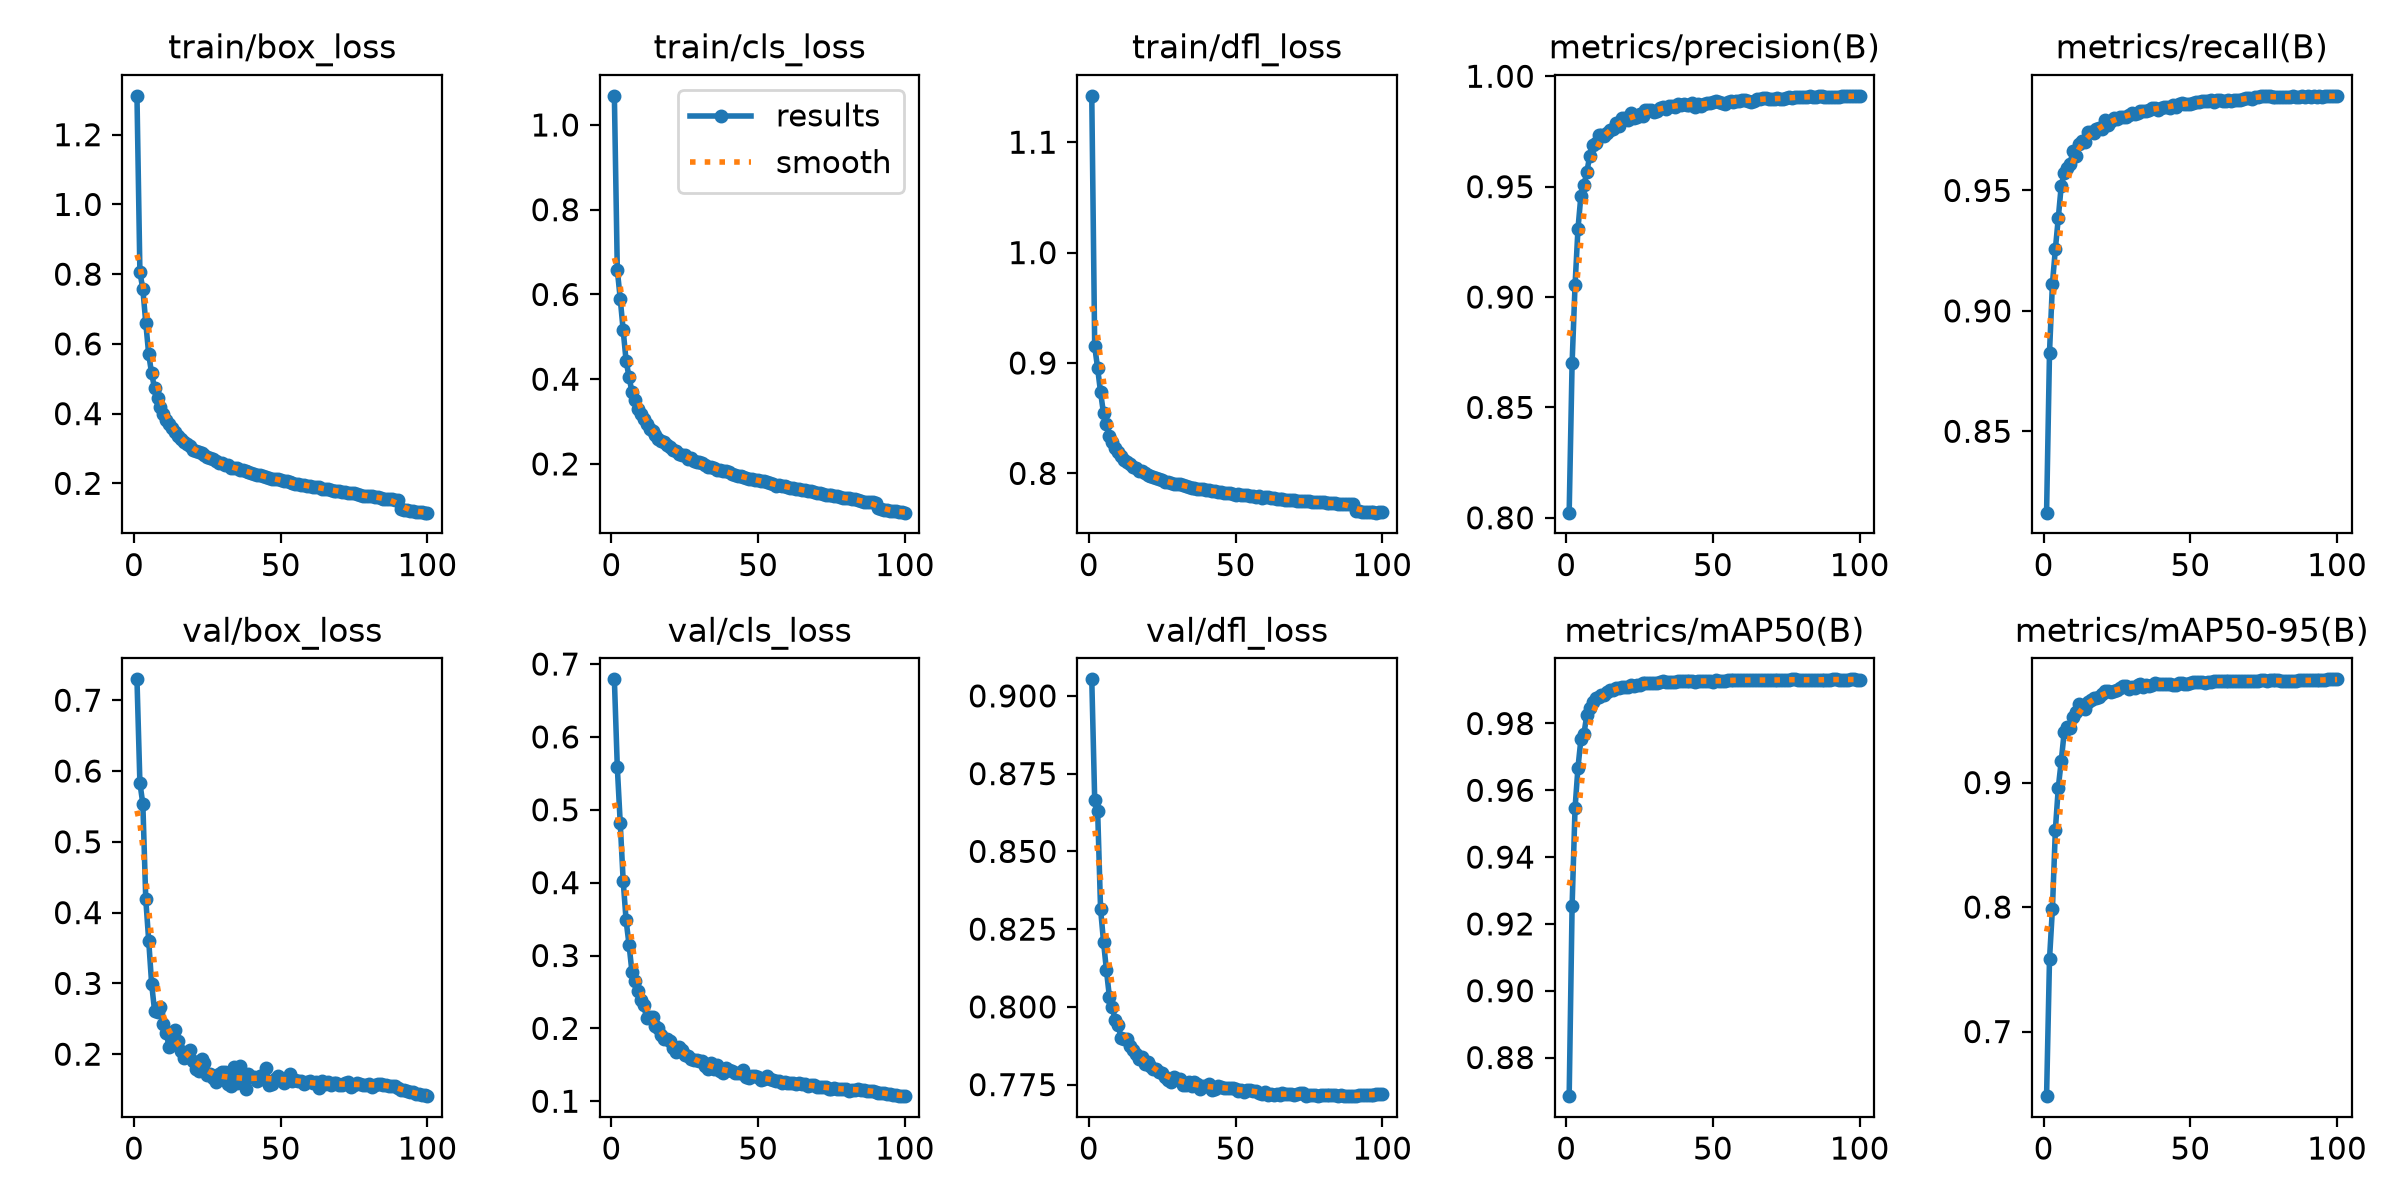

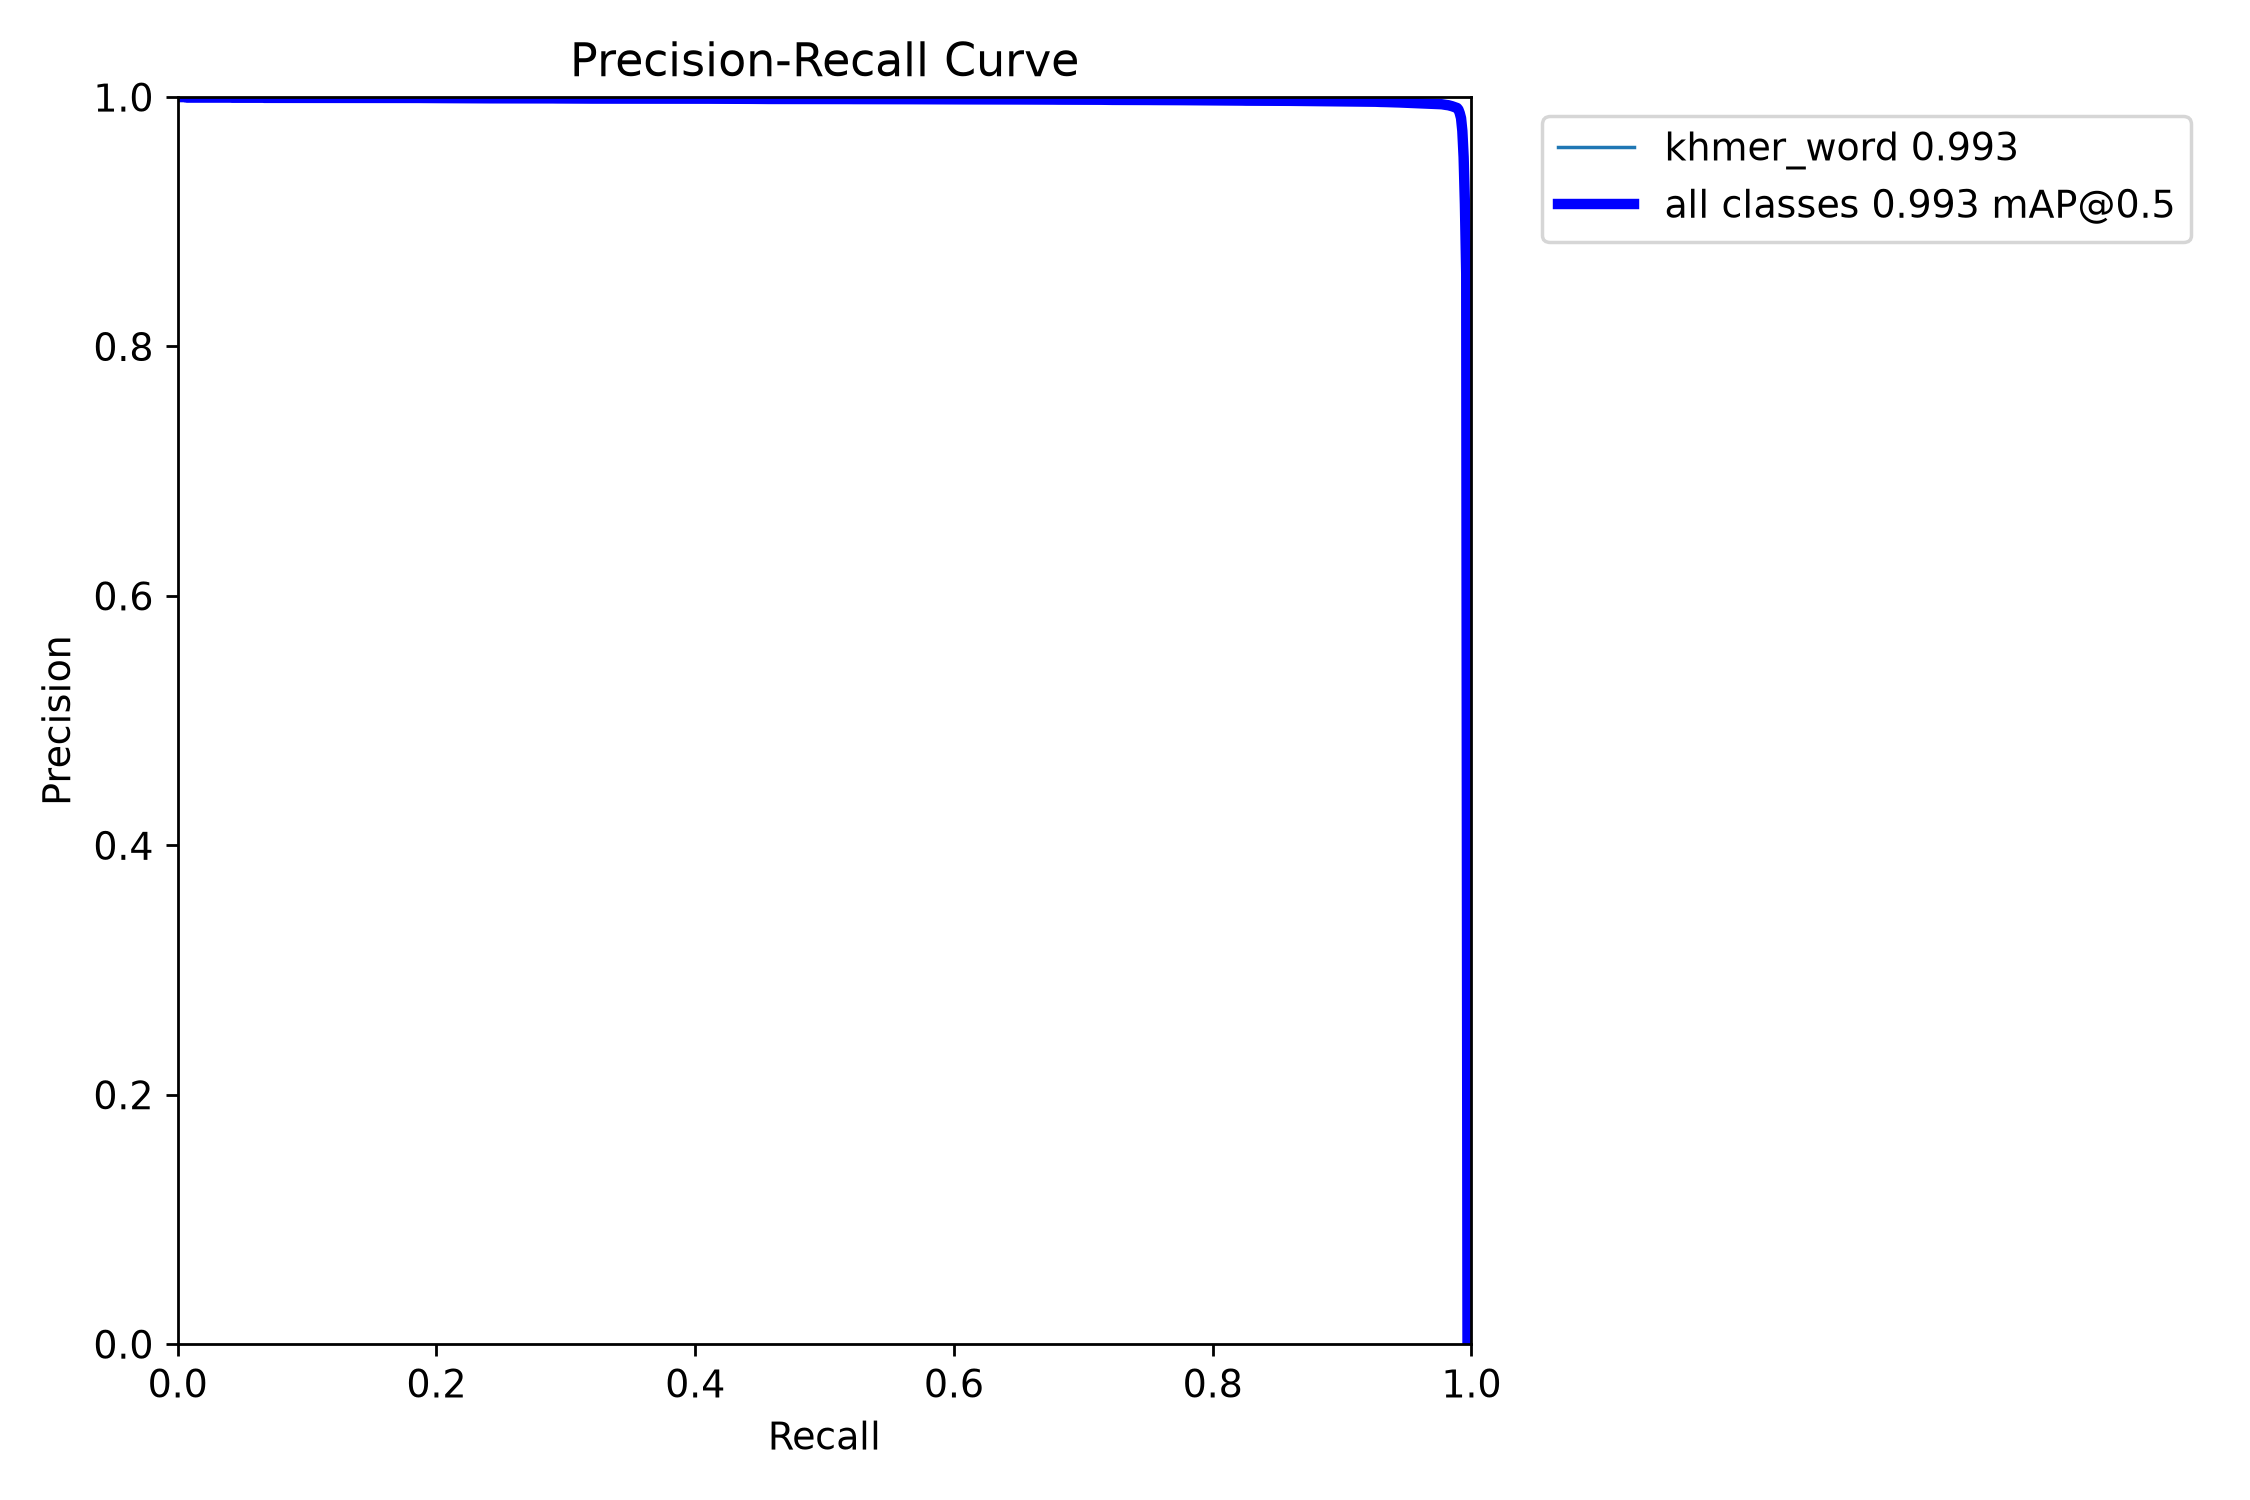

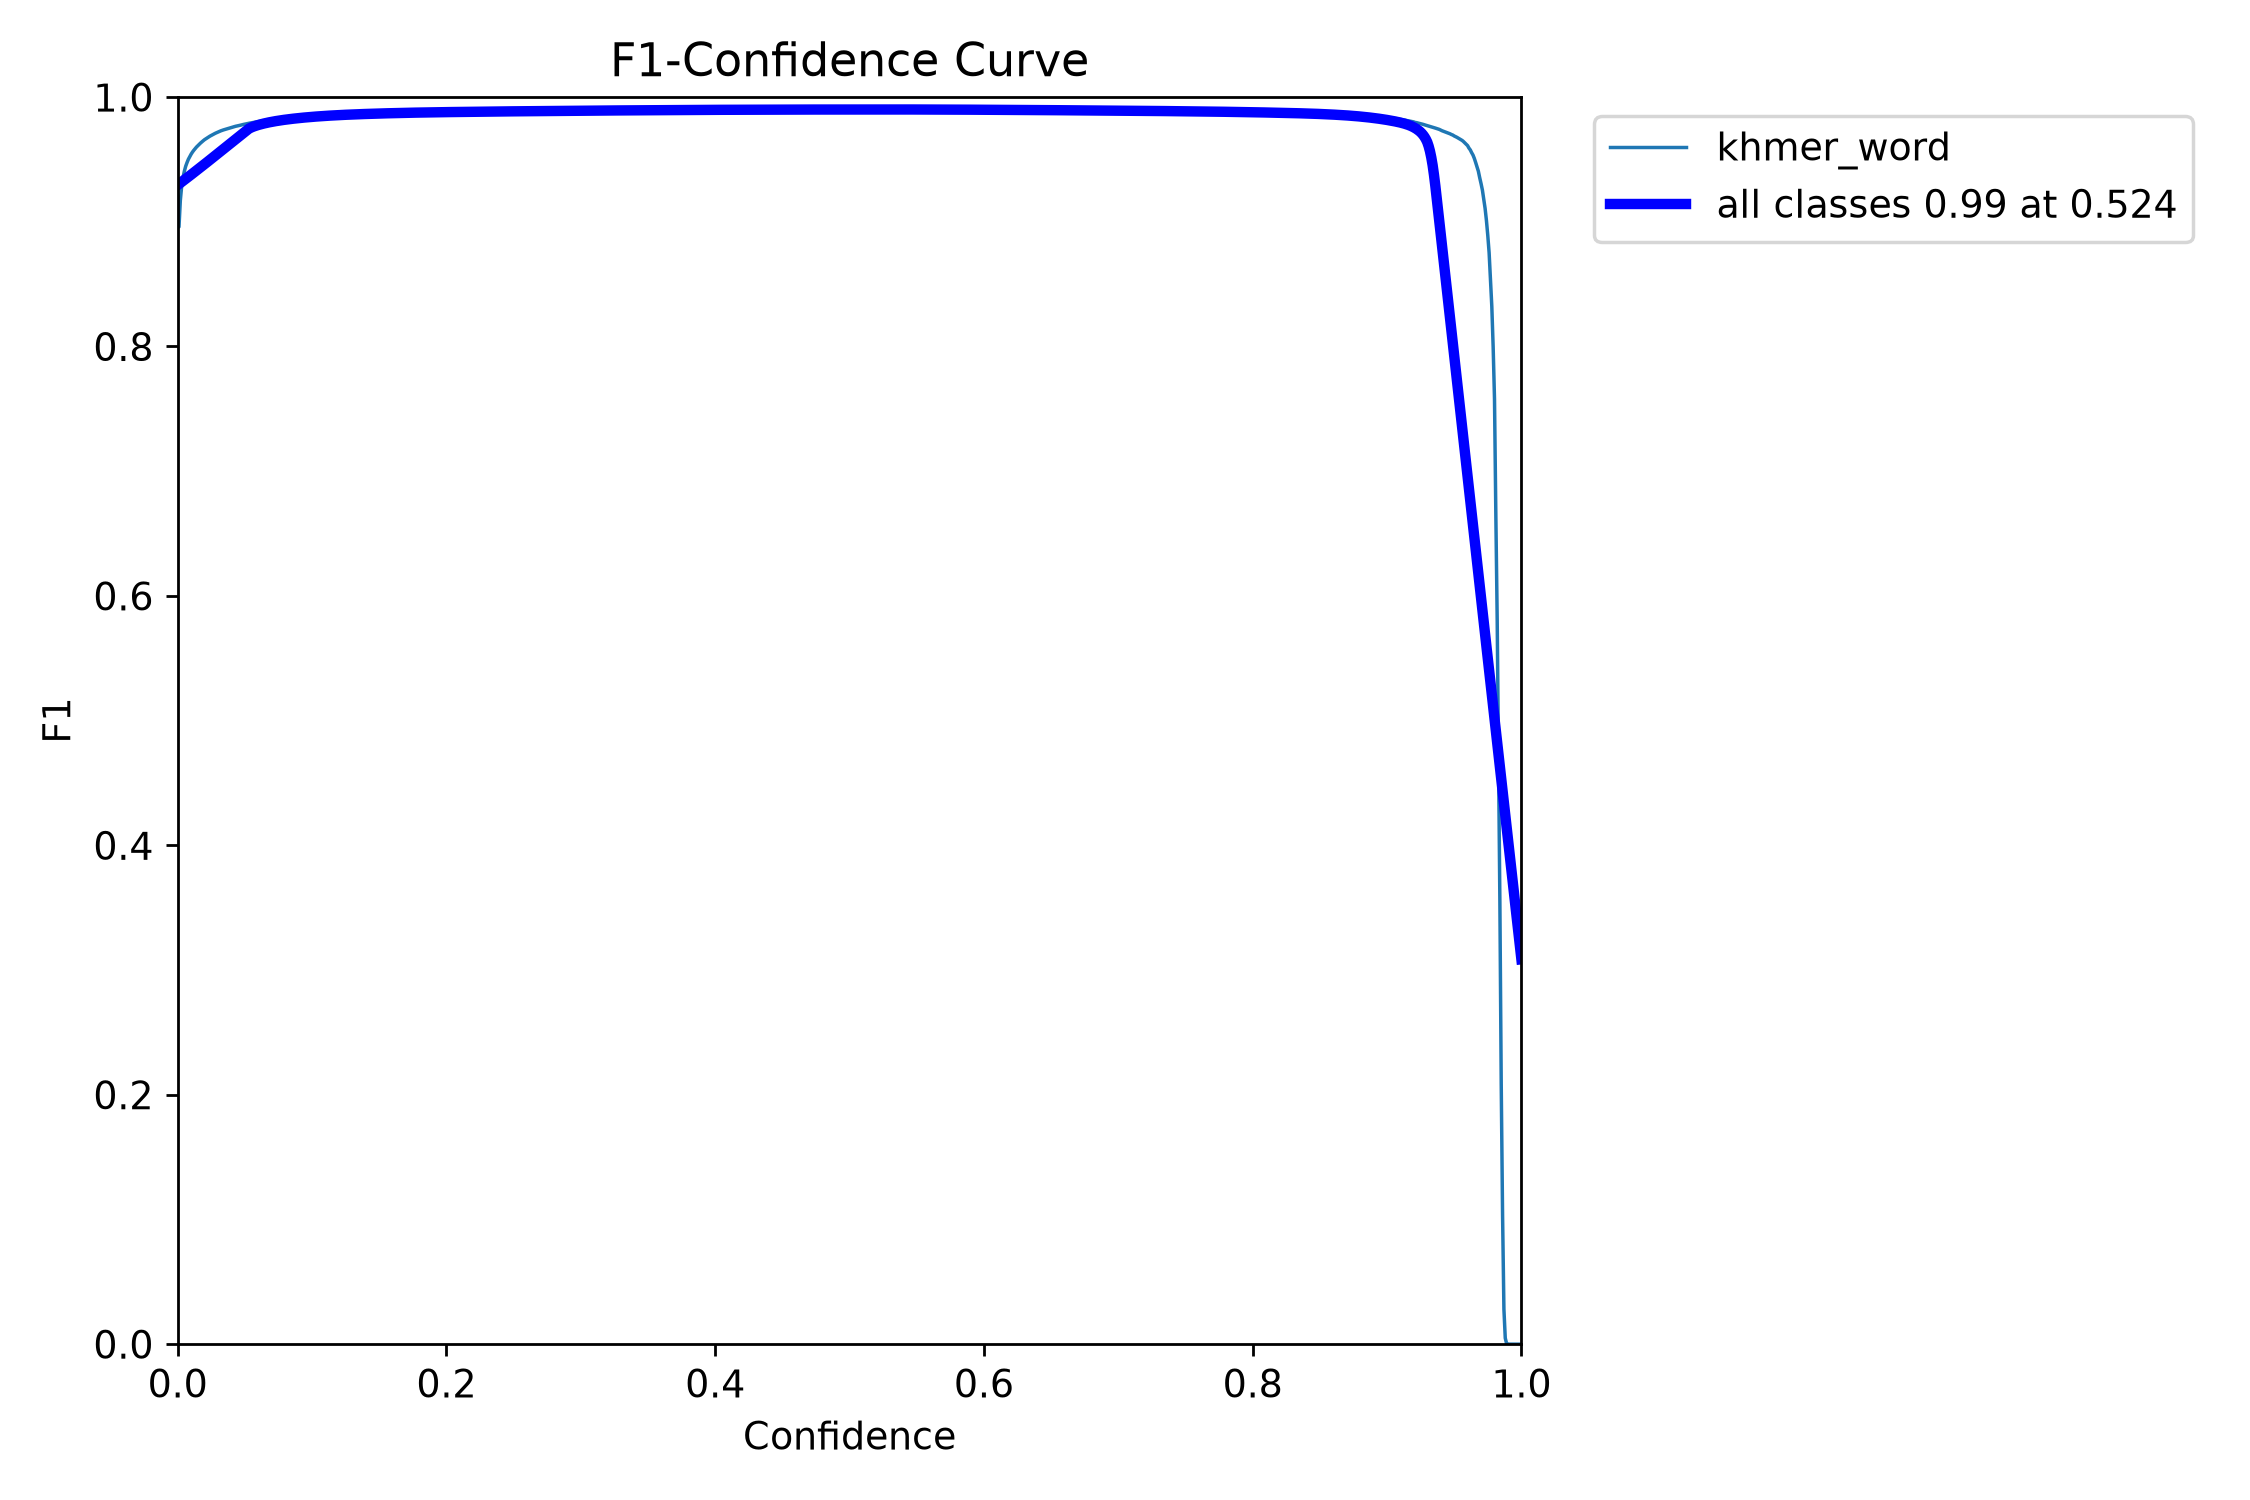

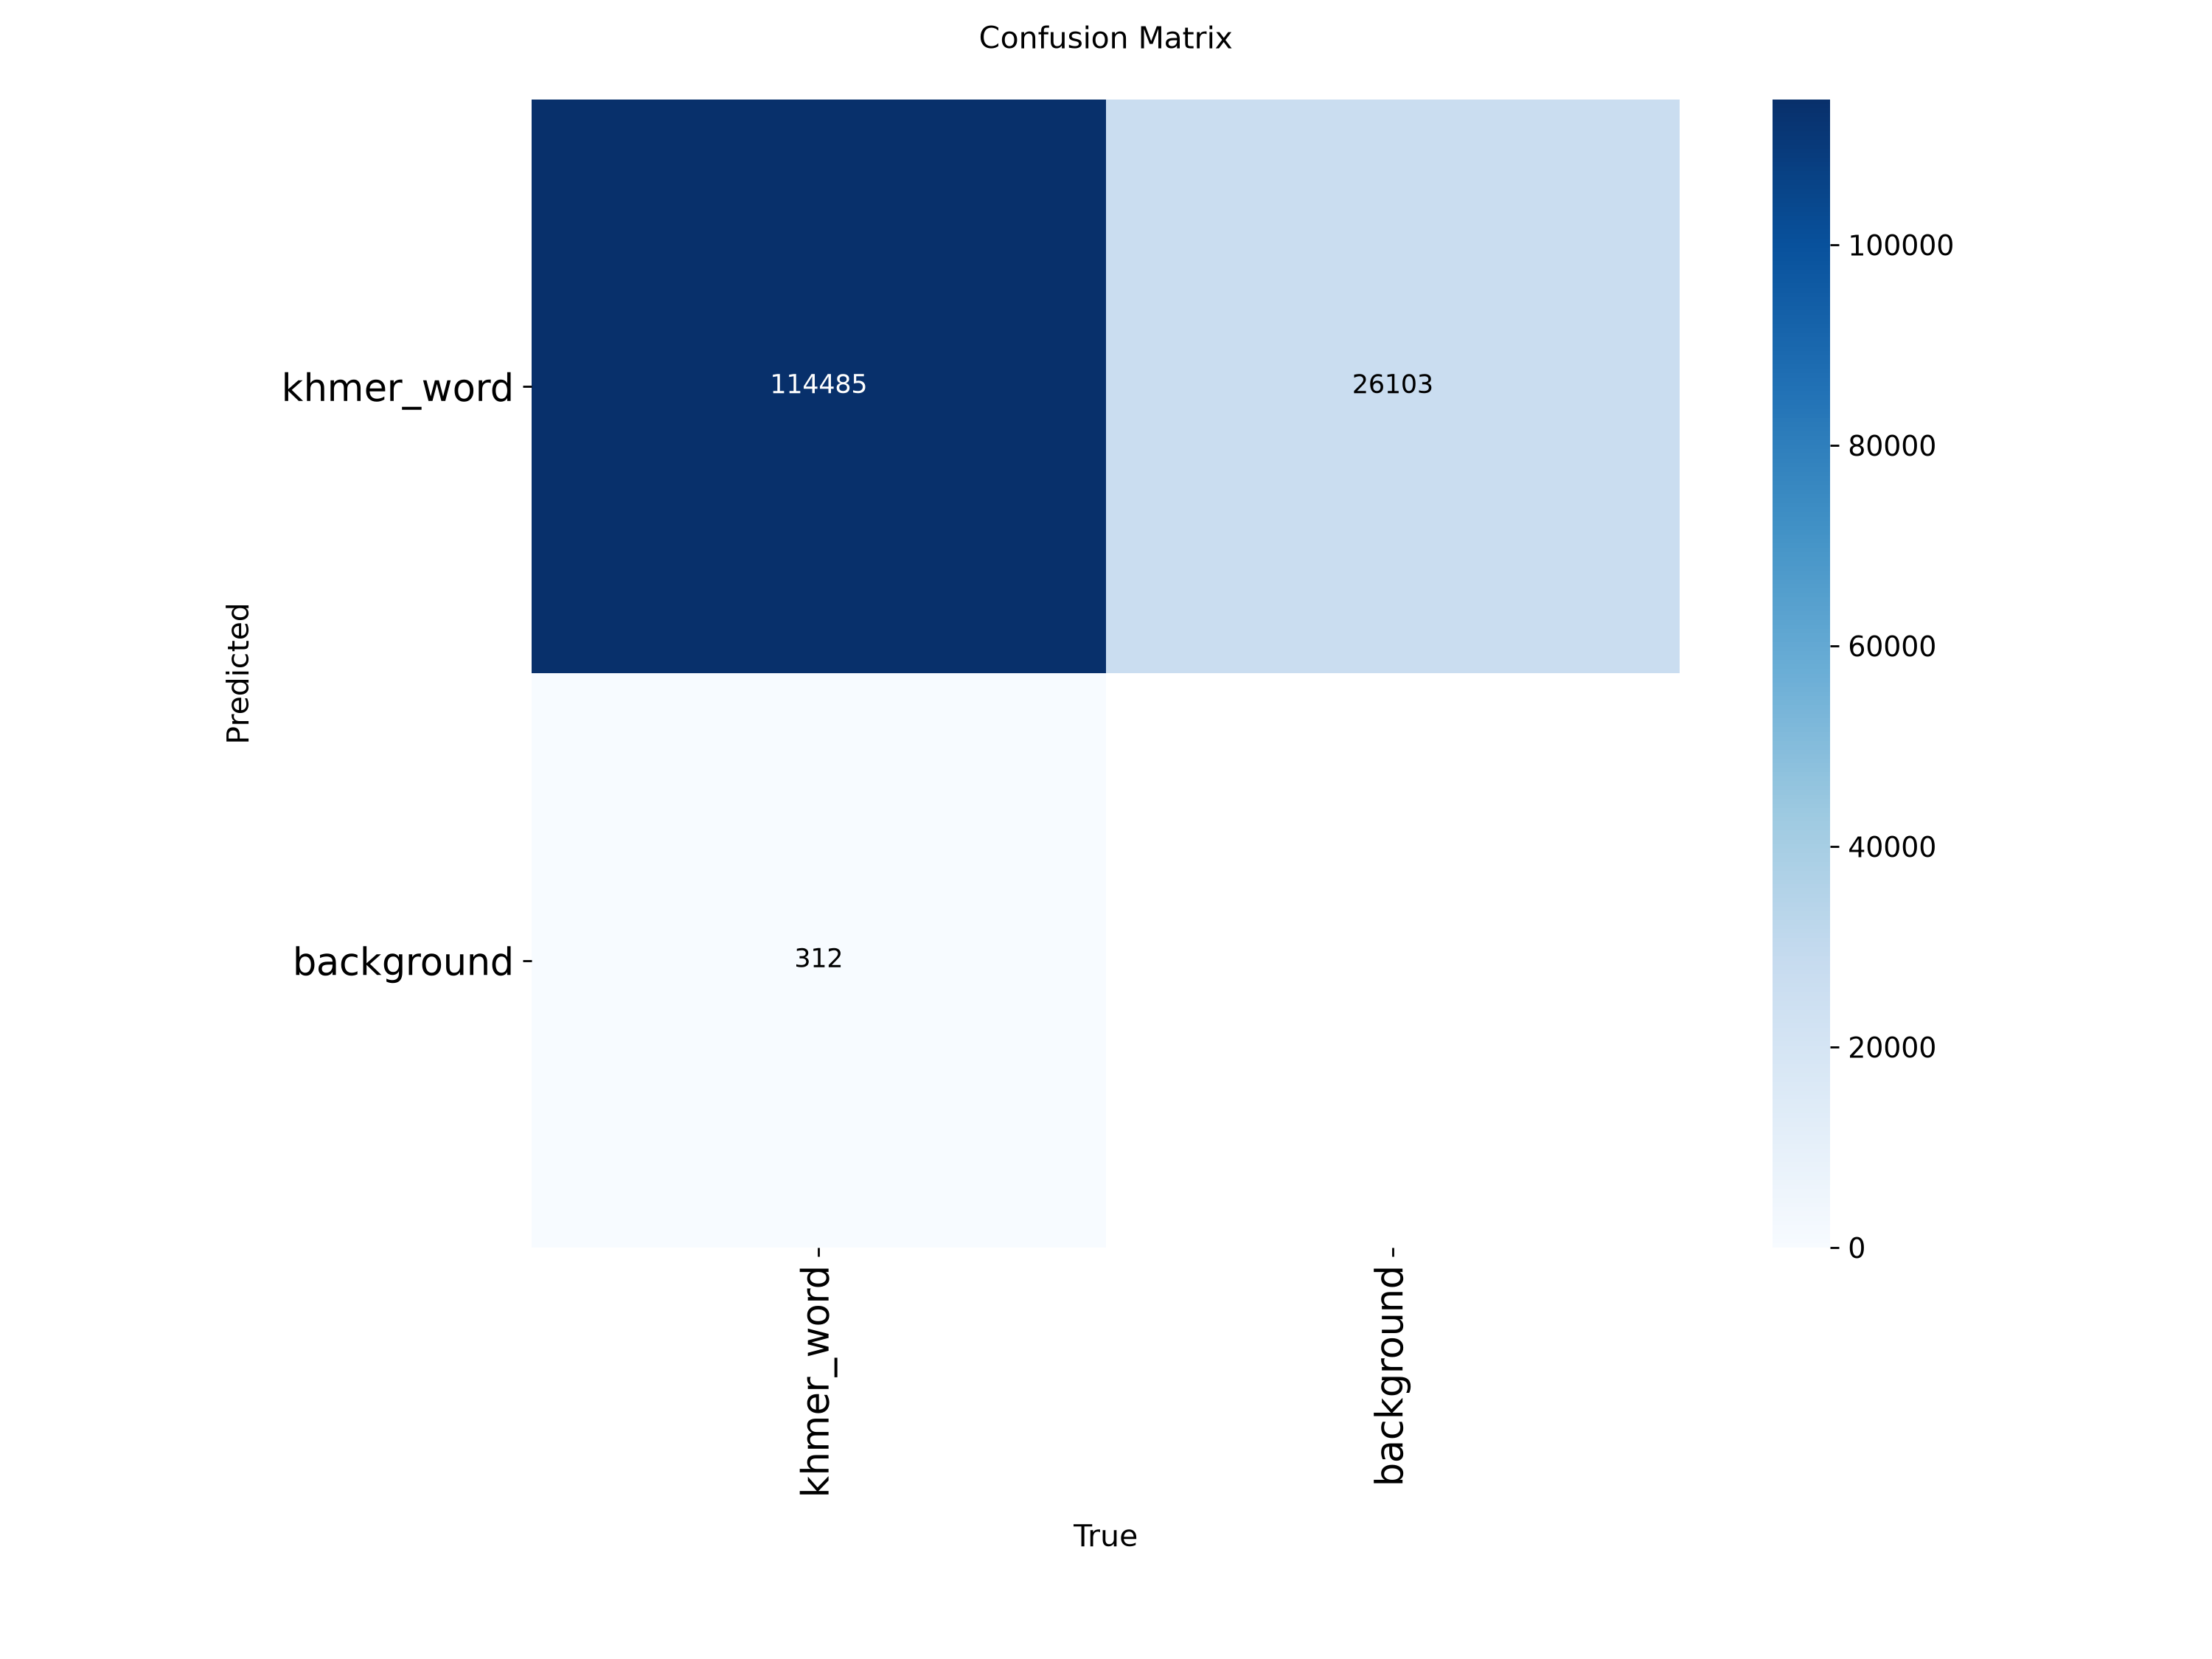

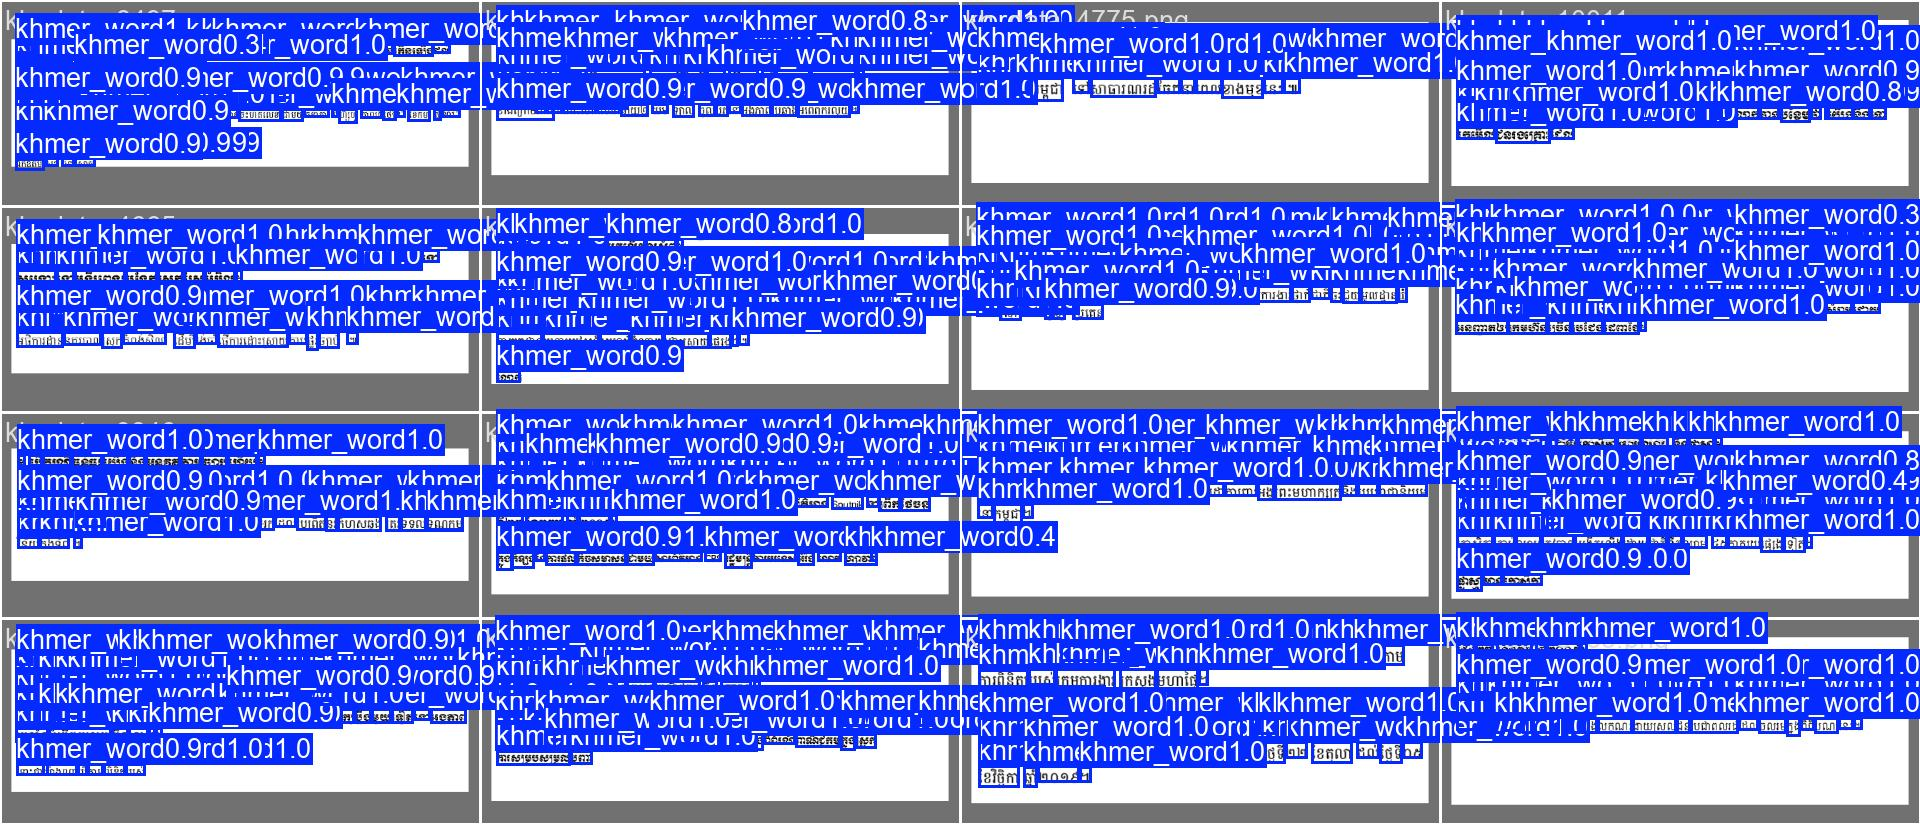

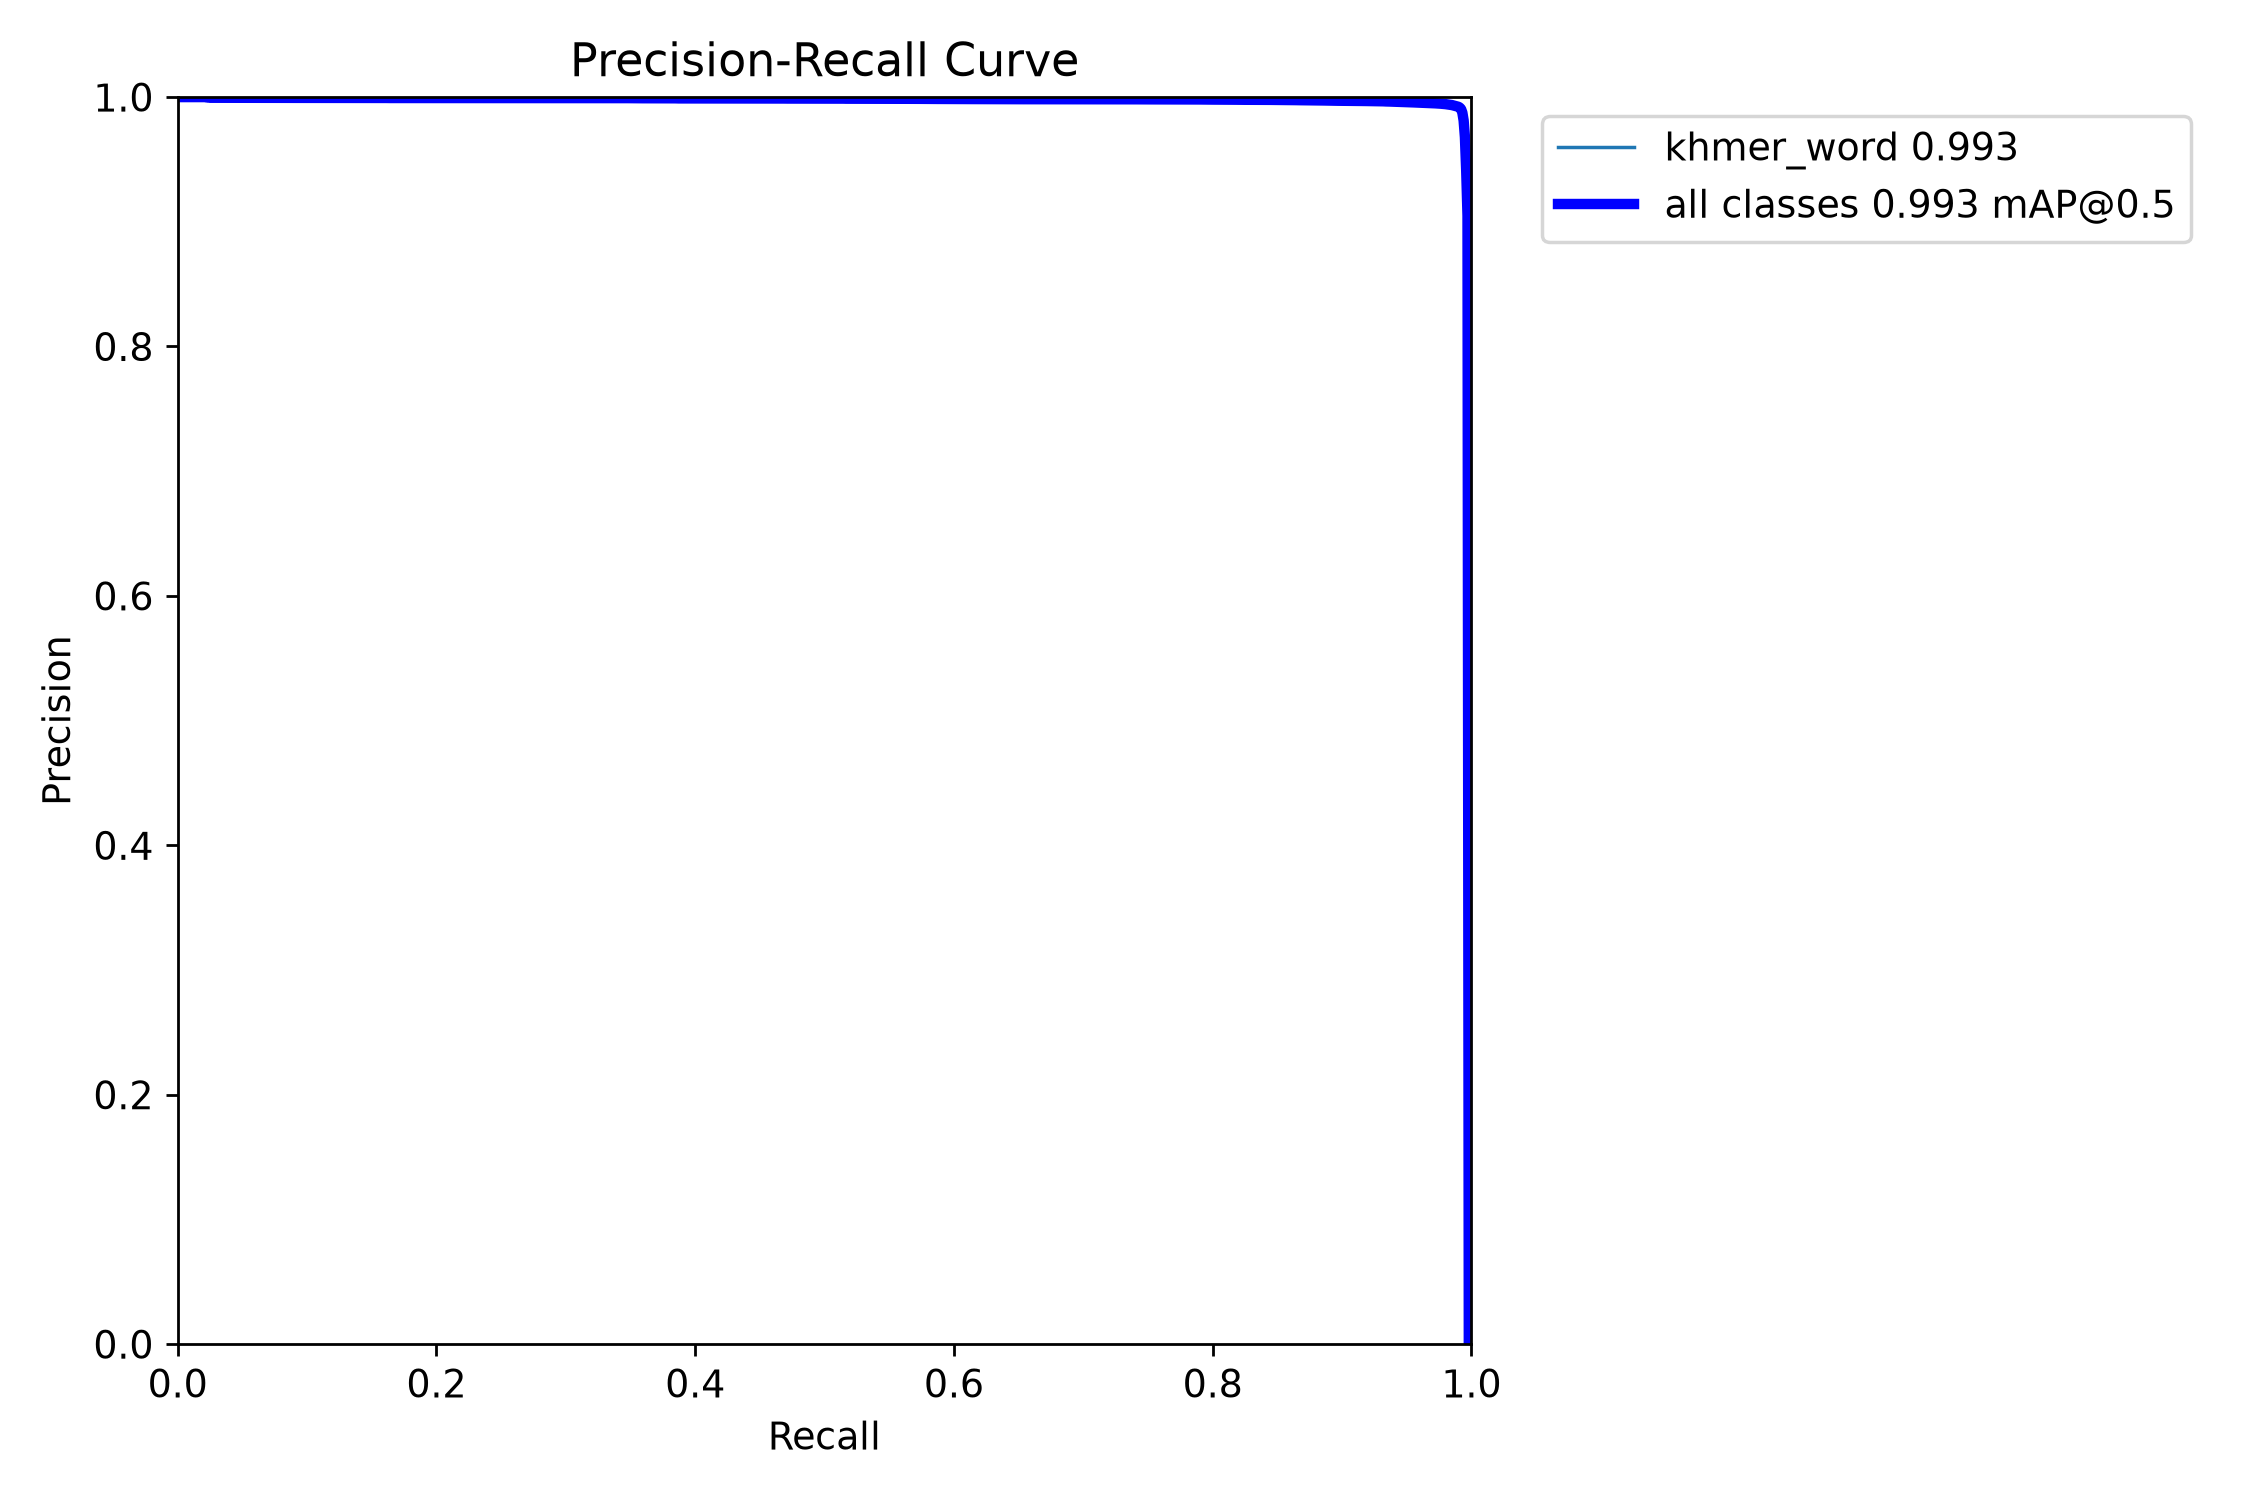

In [15]:
from IPython.display import Image, display
for f in ['results.png', 'BoxPR_curve.png', 'BoxF1_curve.png', 'confusion_matrix.png', 'val_batch0_pred.jpg']:
    display(Image(str(RUN/f), width=800))
display(Image(str(Path(m.save_dir)/'BoxPR_curve.png'), width=800))   # PR curve on the test split

## Predict on a few test pages


0: 640x640 112 khmer_words, 12.2ms
1: 640x640 98 khmer_words, 12.2ms
2: 640x640 104 khmer_words, 12.2ms
Speed: 1.3ms preprocess, 12.2ms inference, 0.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /home/vila/runs/detect/runs/predict


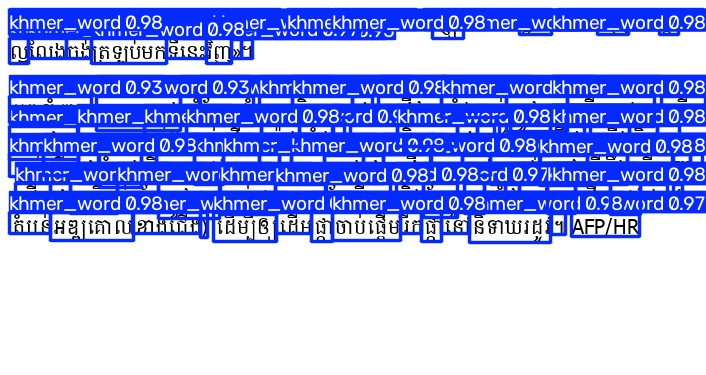

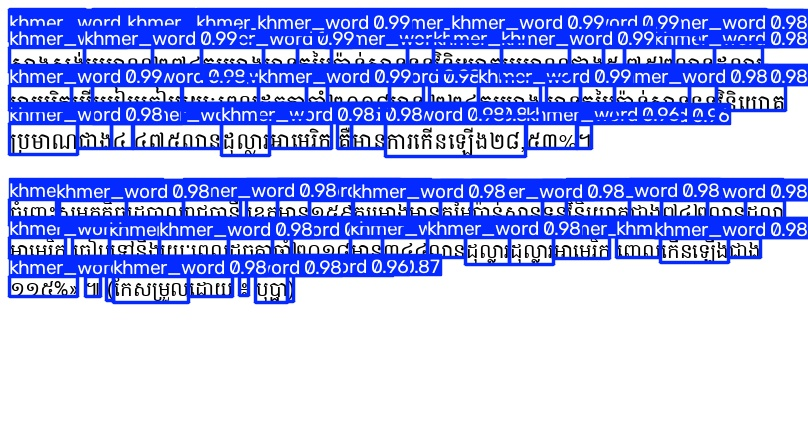

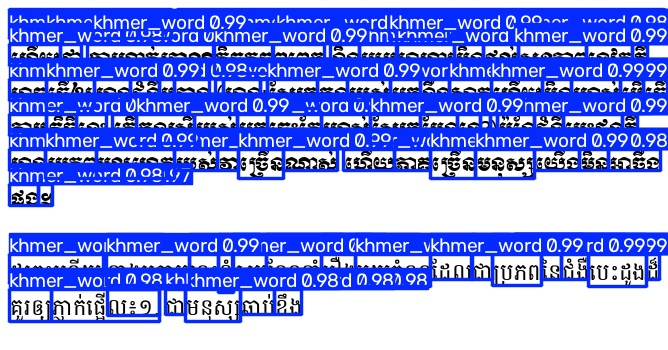

In [13]:
from IPython.display import Image, display
imgs = sorted((OUT/'images'/'test').glob('*'))[:3]
for r in best.predict(imgs, imgsz=IMGSZ, conf=0.25, save=True, project='runs', name='predict', exist_ok=True):
    display(Image(str(Path(r.save_dir)/Path(r.path).name), width=700))

## Export weights
Download `best.pt` to your laptop (Jupyter file browser, or `scp`).

In [14]:
import shutil
print(BEST, LAST)
shutil.make_archive(str(OUT_DIR/'khmer_word_det_weights'), 'zip', RUN/'weights')   # best.pt + last.pt + epochN.pt

/home/vila/khmer-models/khmer_word_det/weights/best.pt /home/vila/khmer-models/khmer_word_det/weights/last.pt


'/home/vila/khmer-models/khmer_word_det_weights.zip'